# Explainability of RUL prediction models on CMAPSS FD001
This notebook contains the code and the results of our paper on the consistency of explanation methods for remaining useful life (RUL) prediction and on operator trust. Three models (a CNN, an LSTM with attention and a hybrid CNN-LSTM-BiLSTM) are explained with Integrated Gradients, Occlusion, LRP (CNN only) and activation maximization, and the explanations are compared within each model and across the models. The last section analyses the trust study. All the code is in this notebook; nothing is imported from other files of the repository.

1. Data import and preprocessing (FD001 only)
2. CNN model
3. LSTM model
4. Hybrid model
5. Explanation methods and attribution maps
6. Within-model agreement results
7. Cross-model agreement results
8. Agreement with the physical sensor trends
9. Sensitivity and infidelity results
10. Activation maximization results
11. Model prediction sensitivity results
12. Trust study results

**How to run it.** Start Jupyter in the `notebooks` folder. The three models were trained in `data_preprocessing.ipynb`, and their weights are saved in `data/` (`cnn_model.pth`, `model.pth` for the LSTM, `hybrid_model.pth`). This notebook does not train anything; it loads these weights, so it gives the same results as the paper. The first run computes the attribution maps and the sensitivity and infidelity values, which takes about 15 minutes on a laptop CPU. They are saved in `results/cache/`, so later runs take a few minutes. The figures are shown here and also saved as PDF files in `results/figures/`.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")      # tqdm (used by Captum) asks for ipywidgets

import copy
import os
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from captum.attr import IntegratedGradients, LRP, Occlusion
from captum.attr._utils.lrp_rules import EpsilonRule
from IPython.display import HTML, display
from scipy import stats
from scipy.stats import rankdata, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA, CACHE, FIGS = "../data", "../results/cache", "../results/figures"
for folder in (CACHE, FIGS):
    os.makedirs(folder, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

# settings of the explanation analysis
WINDOW = 50              # cycles per input window
N_CONSISTENCY = 200      # validation windows used for the agreement results
N_EVAL = 50              # windows used for sensitivity, infidelity and output robustness
SIGMA = 0.05             # standard deviation of the Gaussian input noise
LRP_EPS = 1e-3           # epsilon of the LRP epsilon-rule
AM_BOX_SD = 2.0          # activation maximization: every channel stays within +-2 standard deviations

# figure style (sizes in inches, 7.2 is the text width of the paper)
plt.rcParams.update({
    "pdf.fonttype": 42, "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 9,
    "axes.labelsize": 8.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
})
TEXTWIDTH = 7.2
BLUE, RED = "#3b6fb6", "#c0392b"


def save_figure(fig, name):
    fig.savefig(f"{FIGS}/{name}.pdf", bbox_inches="tight")


def show_panels(draw, keys, name, figsize, adjust, titles=None):
    """saves every panel as its own PDF (name_key.pdf) and shows all panels side by side"""
    for key in keys:
        fig, ax = plt.subplots(figsize=figsize)
        draw(ax, key)
        fig.subplots_adjust(**adjust)
        save_figure(fig, name.format(key))
        plt.close(fig)
    fig, axes = plt.subplots(1, len(keys), figsize=(figsize[0] * len(keys), figsize[1]))
    for ax, key in zip(np.atleast_1d(axes), keys):
        draw(ax, key)
        ax.set_title(titles[key] if titles else key, fontsize=10)
    fig.tight_layout()
    plt.show()

## 1. Data import and preprocessing (FD001 only)
FD001 of the NASA CMAPSS data: 100 training engines and 100 test engines, one operating condition and one fault mode. The remaining useful life (RUL) of a cycle is the last cycle of the engine minus the current cycle, clipped at 125. All 24 channels (three operational settings and 21 sensors) are standardized with a scaler fitted on the training file. The engines are divided into training (80 engines) and validation (20 engines) engines, so that no engine appears in both sets. A window is the sensor data of 50 consecutive cycles and its target is the RUL of the cycle that follows it.

In [2]:
COLUMNS = ["machine_id", "cycle"] + [f"operating_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
FEATURES = COLUMNS[2:]

train_df = pd.read_csv(f"{DATA}/train_FD001.txt", sep=" ", header=None).dropna(axis=1)
train_df.columns = COLUMNS
train_df["RUL"] = (train_df.groupby("machine_id")["cycle"].transform("max") - train_df["cycle"]).clip(upper=125)

# channels that never change in FD001 (operating setting 3 and sensors 1, 5, 10, 16, 18, 19)
CONSTANT = [i for i, c in enumerate(FEATURES) if train_df[c].std() < 1e-6]
assert CONSTANT == [2, 3, 7, 12, 18, 20, 21]
ACTIVE = [i for i in range(24) if i not in CONSTANT]
print("constant channels:", [FEATURES[i] for i in CONSTANT])

scaler = StandardScaler()
train_df[FEATURES] = scaler.fit_transform(train_df[FEATURES])

train_ids, val_ids = train_test_split(train_df["machine_id"].unique(), test_size=0.2, random_state=42)


def make_windows(frame, ids):
    X, y = [], []
    for engine in ids:
        engine_df = frame[frame["machine_id"] == engine]
        values, rul = engine_df[FEATURES].values, engine_df["RUL"].values
        for i in range(len(engine_df) - WINDOW):
            X.append(values[i:i + WINDOW])
            y.append(rul[i + WINDOW])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


X_train, y_train = make_windows(train_df, train_ids)
X_val, y_val = make_windows(train_df, val_ids)
print(f"training windows {X_train.shape}, validation windows {X_val.shape}")
print(f"{len(train_ids)} training engines, {len(val_ids)} validation engines")

constant channels: ['operating_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
training windows (12561, 50, 24), validation windows (3070, 50, 24)
80 training engines, 20 validation engines


The test set has one window per test engine: the last 50 cycles (the first cycle is repeated if an engine has fewer than 50 cycles). The true RUL at the end of each test trajectory is given in `RUL_FD001.txt` and clipped at 125 as well.

In [3]:
test_df = pd.read_csv(f"{DATA}/test_FD001.txt", sep=r"\s+", header=None, names=COLUMNS)
windows = []
for _, engine_df in test_df.groupby("machine_id"):
    values = engine_df[FEATURES].values[-WINDOW:]
    if len(values) < WINDOW:
        values = np.vstack([np.repeat(values[:1], WINDOW - len(values), axis=0), values])
    windows.append(values)
windows = np.array(windows).reshape(-1, 24)
X_test = scaler.transform(pd.DataFrame(windows, columns=FEATURES)).reshape(-1, WINDOW, 24)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = np.minimum(np.loadtxt(f"{DATA}/RUL_FD001.txt"), 125).astype(np.float32)
X_val = torch.tensor(X_val)
print("test windows", tuple(X_test.shape))

test windows (100, 50, 24)


**Evaluation of the models.** Besides RMSE and MAE, the prediction is turned into a maintenance risk class: HIGH if the RUL is below 40 cycles, MEDIUM below 80 and LOW otherwise. "HIGH" errors are the errors on windows whose true RUL is below 40, where a wrong prediction is most costly. The S-score is the asymmetric CMAPSS score of Saxena et al. (2008), which punishes a late prediction more than an early one.

In [4]:
def predict(f, X):
    with torch.no_grad():
        return torch.cat([f(X[i:i + 512]) for i in range(0, len(X), 512)]).squeeze().numpy()


def risk_class(rul):
    return np.where(rul < 40, 0, np.where(rul < 80, 1, 2))     # 0 = HIGH, 1 = MEDIUM, 2 = LOW


def cmapss_score(error):
    return np.where(error < 0, np.exp(-error / 13) - 1, np.exp(error / 10) - 1)


def performance(f, X, y, with_score=False):
    error, high = predict(f, X) - y, y < 40
    out = {"RMSE": np.sqrt((error ** 2).mean()), "MAE": np.abs(error).mean(),
           "RMSE (HIGH)": np.sqrt((error[high] ** 2).mean()), "MAE (HIGH)": np.abs(error[high]).mean(),
           "Risk accuracy (%)": 100 * (risk_class(predict(f, X)) == risk_class(y)).mean()}
    if with_score:
        out["S-score (mean)"] = cmapss_score(error).mean()
    return out


PERFORMANCE = {}


def load_model(model, forward, saved_file, name):
    """Loads the saved weights of the paper and evaluates the model on the validation and the test set."""
    model.load_state_dict(torch.load(f"{DATA}/{saved_file}", map_location="cpu"))
    model.eval()
    PERFORMANCE[name] = {"validation": performance(forward, X_val, y_val), "test": performance(forward, X_test, y_test, True)}
    return pd.DataFrame(PERFORMANCE[name]).round(2)

## 2. CNN model
A 1-D convolutional network on the window: two convolution layers (32 filters of width 5, then 16 filters of width 3) with ReLU, a fully connected layer of 64 units with dropout 0.2, and a linear output that gives the RUL. Every ReLU is its own module, which Captum's LRP requires. Training: Adam (learning rate 0.001), MSE loss, batch size 64, gradient clipping at 1.0, at most 30 epochs with early stopping (patience 5); the weights of the epoch with the lowest validation loss are kept.

In [5]:
class CNNModel(nn.Module):
    def __init__(self, input_size=24, seq_len=WINDOW):
        super().__init__()
        self.conv1 = nn.Conv1d(input_size, 32, kernel_size=5, padding=2)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv1d(32, 16, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.fc1 = nn.Linear(16 * seq_len, 64)
        self.relu3 = nn.ReLU()
        self.drop = nn.Dropout(0.2)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = x.permute(0, 2, 1)                  # (batch, channels, time) for Conv1d
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        x = x.flatten(1)
        x = self.drop(self.relu3(self.fc1(x)))
        return self.fc2(x).squeeze(-1)


cnn = CNNModel()
load_model(cnn, cnn, "cnn_model.pth", "cnn")

,validation,test
RMSE,13.36,15.78
MAE,10.26,11.83
RMSE (HIGH),6.62,7.01
MAE (HIGH),5.26,5.21
Risk accuracy (%),86.12,91.00
S-score (mean),NaN,4.96


## 3. LSTM model
A two-layer LSTM (96 hidden units, dropout 0.2) followed by additive attention over the 50 time steps: a linear layer scores every hidden state, a softmax turns the scores into weights, and the weighted sum of the hidden states goes to a linear output. The model returns the RUL and the attention weights; the explanation methods use the RUL only. Training: the same settings as the CNN.

In [6]:
class LSTMAttentionModel(nn.Module):
    def __init__(self, input_size=24, hidden_size=96):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=2, batch_first=True, dropout=0.2)
        self.attention = nn.Linear(hidden_size, 1)
        self.regressor = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        weights = torch.softmax(self.attention(out), dim=1)
        context = torch.sum(weights * out, dim=1)
        return self.regressor(context).squeeze(-1), weights


lstm = LSTMAttentionModel()
lstm_rul = lambda x: lstm(x)[0]                 # the RUL only
load_model(lstm, lstm_rul, "model.pth", "lstm")

,validation,test
RMSE,12.66,15.59
MAE,9.69,11.17
RMSE (HIGH),5.22,4.58
MAE (HIGH),3.72,3.64
Risk accuracy (%),84.72,88.00
S-score (mean),NaN,3.45


## 4. Hybrid model
Three convolution blocks (32, 64 and 128 filters of width 3, with ReLU and dropout), a three-layer LSTM (96 units), a two-layer bidirectional LSTM (64 units per direction) and a small regression head; the output is taken at the last time step. The structure follows Hong et al. (2020). Training: the same settings, with at most 50 epochs and early stopping with patience 7.

In [7]:
class HybridCNNLSTMBiLSTM(nn.Module):
    def __init__(self, input_size=24, cnn_channels=(32, 64, 128), lstm_hidden=96, lstm_layers=3,
                 bilstm_hidden=64, bilstm_layers=2, dropout=0.2):
        super().__init__()
        c = cnn_channels
        self.cnn = nn.Sequential(
            nn.Conv1d(input_size, c[0], kernel_size=3, padding=1), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(c[0], c[1], kernel_size=3, padding=1), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(c[1], c[2], kernel_size=3, padding=1), nn.ReLU(), nn.Dropout(dropout))
        self.lstm = nn.LSTM(c[2], lstm_hidden, num_layers=lstm_layers, batch_first=True, dropout=dropout)
        self.bilstm = nn.LSTM(lstm_hidden, bilstm_hidden, num_layers=bilstm_layers, batch_first=True,
                              bidirectional=True, dropout=dropout)
        self.regressor = nn.Sequential(nn.Linear(bilstm_hidden * 2, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x):
        x = self.cnn(x.transpose(1, 2)).transpose(1, 2)
        x, _ = self.lstm(x)
        x, _ = self.bilstm(x)
        return self.regressor(x[:, -1, :]).squeeze(-1)


hybrid = HybridCNNLSTMBiLSTM()
load_model(hybrid, hybrid, "hybrid_model.pth", "hybrid")

,validation,test
RMSE,12.64,15.78
MAE,9.59,11.29
RMSE (HIGH),7.28,8.11
MAE (HIGH),5.86,5.84
Risk accuracy (%),86.45,91.00
S-score (mean),NaN,4.20


**Performance of the three models.** Validation: the 3070 windows of the 20 held-out engines. Test: the 100 test engines.

In [8]:
names = {"cnn": "CNN", "lstm": "LSTM", "hybrid": "Hybrid"}
rows = {}
for metric in ["RMSE", "MAE", "RMSE (HIGH)", "MAE (HIGH)", "Risk accuracy (%)"]:
    rows[metric] = [PERFORMANCE[m]["validation"][metric] for m in names] + [PERFORMANCE[m]["test"][metric] for m in names]
rows["S-score (mean)"] = [np.nan] * 3 + [PERFORMANCE[m]["test"]["S-score (mean)"] for m in names]
table4 = pd.DataFrame(rows, index=pd.MultiIndex.from_product([["Validation", "Test"], names.values()])).T
display(table4.round(2))

Validation                 Test              
                         CNN   LSTM Hybrid    CNN   LSTM Hybrid
RMSE                   13.36  12.66  12.64  15.78  15.59  15.78
MAE                    10.26   9.69   9.59  11.83  11.17  11.29
RMSE (HIGH)             6.62   5.22   7.28   7.01   4.58   8.11
MAE (HIGH)              5.26   3.72   5.86   5.21   3.64   5.84
Risk accuracy (%)      86.12  84.72  86.45  91.00  88.00  91.00
S-score (mean)           NaN    NaN    NaN   4.96   3.45   4.20

## 5. Explanation methods and attribution maps
Every method gives, for a window of shape (50, 24), a map of the same shape.

- **Integrated Gradients (IG)** with a zero baseline (the training mean after standardization) and 50 steps.
- **Occlusion** of one value at a time (one sensor in one cycle), replaced by zero.
- **LRP** with the epsilon rule (epsilon = 0.001), written here for the CNN only. Convolution and linear layers use the epsilon rule and the ReLU passes relevance through unchanged. It is computed as a "modified gradient": the relevance of the input is `x * dy/dx` on a copy of the forward pass in which every ReLU is given the backward multiplier `relu(z) / (z + eps*sign(z))`. The LSTM and the hybrid model are not explained with LRP in the paper.
- **Activation maximization** is not an attribution method and is in Section 10.

All agreement results use the same sample of 200 validation windows (drawn with a fixed seed). The maps are computed once and saved in `results/cache/maps.npz`.

In [9]:
MODELS = ["cnn", "lstm", "hybrid"]
LABEL = {"cnn": "CNN", "lstm": "LSTM", "hybrid": "Hybrid", "ig": "IG", "occlusion": "Occlusion", "lrp": "LRP"}
FN = {"cnn": cnn, "lstm": lstm_rul, "hybrid": hybrid}
METHODS = ["ig", "occlusion", "lrp"]
SHOWN = {"cnn": ["ig", "occlusion", "lrp"], "lstm": ["ig", "occlusion"], "hybrid": ["ig", "occlusion"]}   # LRP: CNN only
for m in (cnn, lstm, hybrid):
    m.eval()


def _sign(z):
    return torch.where(z >= 0, torch.ones_like(z), -torch.ones_like(z))


def _stabilize(z, eps):
    return z + eps * _sign(z)


def _relu_lrp(z, eps):
    """forward: relu(z); backward multiplier: relu(z) / (z + eps*sign(z))"""
    a = F.relu(z)
    return a.detach() + (z - z.detach()) * (a / _stabilize(z, eps)).detach()


def lrp_cnn(model, x, eps=LRP_EPS):
    """epsilon-LRP relevance of every input value of the CNN, shape (batch, 50, 24)."""
    p = lambda t: t.detach().double()
    x = x.detach().double().clone().requires_grad_(True)
    z = x.transpose(1, 2)
    z = _relu_lrp(F.conv1d(z, p(model.conv1.weight), p(model.conv1.bias), padding=model.conv1.padding), eps)
    z = _relu_lrp(F.conv1d(z, p(model.conv2.weight), p(model.conv2.bias), padding=model.conv2.padding), eps)
    z = _relu_lrp(z.flatten(1) @ p(model.fc1.weight).T + p(model.fc1.bias), eps)
    y = (z @ p(model.fc2.weight).T + p(model.fc2.bias)).squeeze(-1)
    grad = torch.autograd.grad(y, x, grad_outputs=(y / _stabilize(y, eps)).detach())[0]
    return (x * grad).detach()


def attribute(model_name, method, x, batch=100):
    """x: (batch, 50, 24) -> attribution map of the same shape (numpy)."""
    if method == "ig":
        out = IntegratedGradients(FN[model_name]).attribute(x, baselines=torch.zeros_like(x), n_steps=50, internal_batch_size=1000)
    elif method == "occlusion":
        out = Occlusion(FN[model_name]).attribute(x, baselines=0, sliding_window_shapes=(1, 1), strides=(1, 1), perturbations_per_eval=batch)
    elif method == "lrp":
        assert model_name == "cnn", "LRP is implemented for the CNN only"
        out = lrp_cnn(cnn, x)
    return out.detach().float().numpy()


np.random.seed(SEED)
IDX = np.random.choice(len(X_val), size=N_CONSISTENCY, replace=False)     # the 200 validation windows of the analysis

**Check of the LRP implementation.** (i) Our CNN relevance equals the output of Captum's epsilon-LRP. (ii) With all biases set to zero the relevance at the input sums to the model output (the conservation property of LRP).

In [10]:
sample = X_val[IDX[:12]]

captum_cnn = copy.deepcopy(cnn)
for module in captum_cnn.modules():
    if isinstance(module, (nn.Conv1d, nn.Linear, nn.ReLU, nn.Dropout)):
        module.rule = EpsilonRule()
captum_relevance = LRP(captum_cnn).attribute(sample.clone()).detach().double()
own_relevance = lrp_cnn(cnn, sample, eps=1e-9)
print("own LRP vs. Captum LRP, relative error:", float(((captum_relevance - own_relevance).abs().max() / captum_relevance.abs().max())))

no_bias = copy.deepcopy(cnn)
for name, parameter in no_bias.named_parameters():
    if "bias" in name:
        parameter.data.zero_()
relevance = lrp_cnn(no_bias, sample, eps=1e-12)
with torch.no_grad():
    output = no_bias(sample).double()
print("conservation with zero biases, largest relative deviation:", float(((relevance.sum((1, 2)) - output).abs() / output.abs()).max()))

own LRP vs. Captum LRP, relative error: 7.602604007256433e-08
conservation with zero biases, largest relative deviation: 2.585904513955753e-07


In [11]:
def save_maps(path, maps):
    np.savez_compressed(path, idx=IDX, **{f"{m}__{k}": v for (m, k), v in maps.items()})


def compute_maps(windows, chunk=10):
    maps = {}
    for model_name in MODELS:
        for method in SHOWN[model_name]:
            maps[(model_name, method)] = np.concatenate(
                [attribute(model_name, method, X_val[windows[i:i + chunk]]) for i in range(0, len(windows), chunk)])
            print("maps", model_name, method, flush=True)
    return maps


MAPS_FILE = f"{CACHE}/maps.npz"
if os.path.exists(MAPS_FILE):
    saved = np.load(MAPS_FILE)
    assert (saved["idx"] == IDX).all()
    maps = {tuple(k.split("__")): saved[k] for k in saved.files if k != "idx"}
else:
    maps = compute_maps(IDX)
    save_maps(MAPS_FILE, maps)

# check of the saved maps: the first 4 windows are computed again
fresh = compute_maps(IDX[:4])
print("largest difference between the cached maps and the maps computed again:",
      max(float(np.abs(fresh[k] - maps[k][:4]).max()) for k in fresh))
print({f"{m}-{k}": v.shape for (m, k), v in maps.items()})

maps cnn ig
maps cnn occlusion
maps cnn lrp
maps lstm ig
maps lstm occlusion
maps hybrid ig
maps hybrid occlusion
largest difference between the cached maps and the maps computed again: 1.52587890625e-05
{'cnn-ig': (200, 50, 24), 'cnn-occlusion': (200, 50, 24), 'cnn-lrp': (200, 50, 24), 'lstm-ig': (200, 50, 24), 'lstm-occlusion': (200, 50, 24), 'hybrid-ig': (200, 50, 24), 'hybrid-occlusion': (200, 50, 24)}


## 6. Within-model agreement results
For a given model, do different explanation methods point to the same sensors? Each map is reduced to a profile of 24 values per window (the signed attribution averaged over the 50 time steps). The seven constant channels always get zero attribution, so the agreement is computed over the other 17 channels. Two profiles are compared with five metrics:

- **Spearman**: rank correlation of the 17 values.
- **Rank@5**: share of the five top positions occupied by the same sensor.
- **Feature@5**: share of the five most important sensors that both profiles have in common.
- **Sign**: share of sensors with the same sign.
- **Signed-rank@5**: share of the five top positions with the same sensor and the same sign.

The "most important" sensors are the ones with the largest absolute attribution.

In [12]:
METRICS = ["spearman", "rank", "feature", "sign", "signedrank5"]
METRIC_LABEL = {"spearman": "Spearman", "rank": "Rank@5", "feature": "Feature@5", "sign": "Sign", "signedrank5": "Signed-rank@5"}


def agreement(a, b, k=5):
    """the five agreement metrics for two per-sensor profiles a and b"""
    order_a = np.argsort(-np.abs(a), kind="stable")
    order_b = np.argsort(-np.abs(b), kind="stable")
    same_sensor = order_a[:k] == order_b[:k]
    same_sign = np.sign(a[order_a[:k]]) == np.sign(b[order_b[:k]])
    return {"spearman": spearmanr(a, b)[0],
            "rank": same_sensor.mean(),
            "feature": len(set(order_a[:k]) & set(order_b[:k])) / k,
            "sign": np.mean(np.sign(a) == np.sign(b)),
            "signedrank5": (same_sensor & same_sign).mean()}


PROFILE = {key: m.mean(axis=1)[:, ACTIVE] for key, m in maps.items()}      # (windows, 17)


def pair_agreement(key_a, key_b):
    rows = [agreement(a, b) for a, b in zip(PROFILE[key_a], PROFILE[key_b])]
    return {m: np.array([r[m] for r in rows]) for m in METRICS}


def agreement_table(rows, title):
    """rows: list of (labels, metrics). Shows mean ± std over the windows, the largest mean of each column in bold."""
    best = {m: max(np.mean(r[1][m]) for r in rows) for m in METRICS}
    lines = []
    for label, mets in rows:
        cells = []
        for m in METRICS:
            mean, std = np.mean(mets[m]), np.std(mets[m])
            cells.append(f"<b>{mean:.3f}</b> ± {std:.3f}" if abs(mean - best[m]) < 5e-4 else f"{mean:.3f} ± {std:.3f}")
        lines.append("<tr><td>" + "</td><td>".join(list(label) + cells) + "</td></tr>")
    header = "<tr><th>" + "</th><th>".join(title + [METRIC_LABEL[m] for m in METRICS]) + "</th></tr>"
    display(HTML("<table>" + header + "".join(lines) + "</table>"))


WITHIN = {}
for model_name in MODELS:
    for a, b in combinations(SHOWN[model_name], 2):
        WITHIN[(model_name, a, b)] = pair_agreement((model_name, a), (model_name, b))

**Within-model agreement**, mean ± standard deviation over the 200 validation windows. LRP is available for the CNN only.

In [13]:
agreement_table([((LABEL[m], f"{LABEL[a]} vs. {LABEL[b]}"), v) for (m, a, b), v in WITHIN.items()], ["Model", "Method pair"])

Model,Method pair,Spearman,Rank@5,Feature@5,Sign,Signed-rank@5
CNN,IG vs. Occlusion,0.928 ± 0.062,0.262 ± 0.228,0.730 ± 0.171,0.904 ± 0.072,0.262 ± 0.228
CNN,IG vs. LRP,0.934 ± 0.063,0.267 ± 0.241,0.734 ± 0.211,0.875 ± 0.090,0.267 ± 0.241
CNN,Occlusion vs. LRP,0.917 ± 0.067,0.134 ± 0.194,0.626 ± 0.188,0.802 ± 0.096,0.133 ± 0.193
LSTM,IG vs. Occlusion,0.697 ± 0.273,0.249 ± 0.246,0.669 ± 0.229,0.771 ± 0.137,0.246 ± 0.248
Hybrid,IG vs. Occlusion,0.693 ± 0.378,0.276 ± 0.260,0.660 ± 0.256,0.769 ± 0.212,0.268 ± 0.263


**Attribution maps.** Mean absolute attribution of every sensor and time step, averaged over the 200 windows (the color scale differs between panels). The CNN explanations spread over many sensors and time steps; for the LSTM and the hybrid model, IG and Occlusion put most attribution on the last 20 cycles of the window.

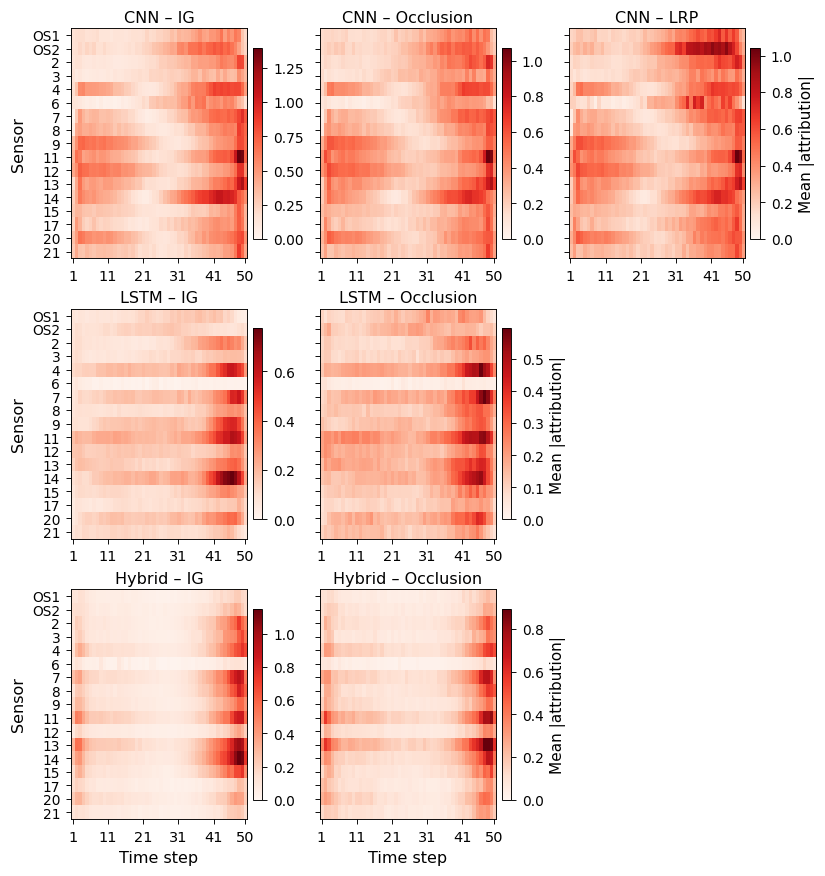

In [14]:
SENSOR_NUM = ["OS1", "OS2", "OS3"] + [str(i + 1) for i in range(21)]


def heatmap_grid():
    fig, axes = plt.subplots(3, 3, figsize=(TEXTWIDTH, 7.9))
    for r, model_name in enumerate(MODELS):
        for c, method in enumerate(METHODS):
            ax = axes[r, c]
            if method not in SHOWN[model_name]:
                ax.axis("off")
                continue
            image = ax.imshow(np.abs(maps[(model_name, method)]).mean(0)[:, ACTIVE].T, aspect="auto", cmap="Reds",
                              interpolation="nearest", vmin=0)
            ax.set_title(f"{LABEL[model_name]} – {LABEL[method]}", fontsize=10.5, pad=4)
            ax.set_xticks([0, 10, 20, 30, 40, 49])
            ax.set_xticklabels([1, 11, 21, 31, 41, 50])
            ax.set_yticks(range(len(ACTIVE)))
            ax.set_yticklabels([SENSOR_NUM[i] for i in ACTIVE] if c == 0 else [], fontsize=9)
            ax.tick_params(axis="x", labelsize=9.5)
            if r == 2:
                ax.set_xlabel("Time step", fontsize=10.5)
            if c == 0:
                ax.set_ylabel("Sensor", fontsize=10.5)
            colorbar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03)
            colorbar.ax.tick_params(labelsize=9)
            if c == 2 or (c == 1 and r > 0):
                colorbar.set_label("Mean |attribution|", fontsize=10)
            for spine in ax.spines.values():
                spine.set_visible(True)
    fig.subplots_adjust(hspace=0.22, wspace=0.3, left=0.07, right=0.94, top=0.96, bottom=0.05)
    save_figure(fig, "agg_heatmap_grid")
    plt.show()


heatmap_grid()

**Radar plot of the within-model agreement.** Each spoke is one comparison and each polygon one metric; the inner circle marks zero.

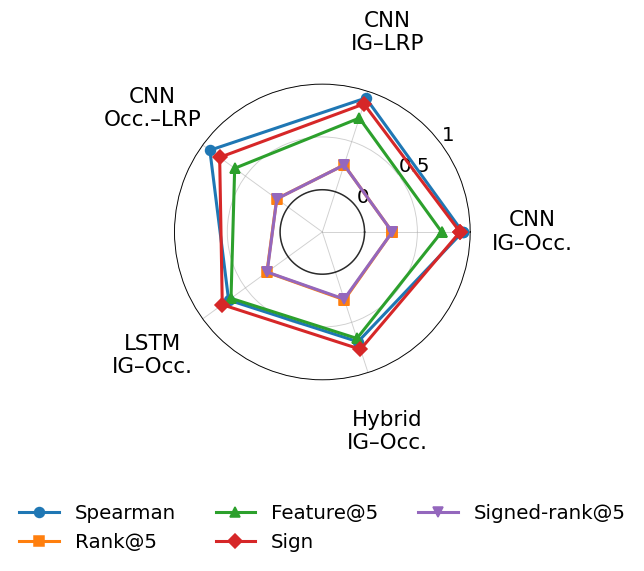

In [15]:
def radar(rows, labels, name):
    n = len(rows)
    angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
    closed = np.concatenate([angles, angles[:1]])
    fig = plt.figure(figsize=(5.6, 6.6))
    ax = fig.add_axes([0.26, 0.31, 0.48, 0.44], polar=True)
    for metric, color, marker in zip(METRICS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"], ["o", "s", "^", "D", "v"]):
        values = np.array([np.mean(r[metric]) for r in rows])
        ax.plot(closed, np.concatenate([values, values[:1]]), color=color, lw=2, marker=marker, ms=6.5, label=METRIC_LABEL[metric])
    ax.set_ylim(-0.4, 1.0)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_yticklabels(["0", "0.5", "1"], fontsize=13, bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.85))
    ax.set_rlabel_position(360 / n / 2)
    ax.set_xticks(angles)
    ax.set_xticklabels(labels, fontsize=14)
    ax.tick_params(axis="x", pad=30)
    ax.spines["polar"].set_visible(True)
    ax.grid(lw=0.6, alpha=0.6)
    ax.plot(np.linspace(0, 2 * np.pi, 200), np.zeros(200), color="k", lw=1.0, alpha=0.8)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.36), ncol=3, fontsize=13, frameon=False)
    save_figure(fig, name)
    plt.show()


short = {"ig": "IG", "occlusion": "Occ.", "lrp": "LRP"}
radar(list(WITHIN.values()), [f"{LABEL[m]}\n{short[a]}–{short[b]}" for (m, a, b) in WITHIN], "radar_within_model")

**Distribution over the windows.** The mean hides how much the agreement changes from window to window. Histograms of the five metrics for the CNN, IG vs. Occlusion (the dashed line is the mean).

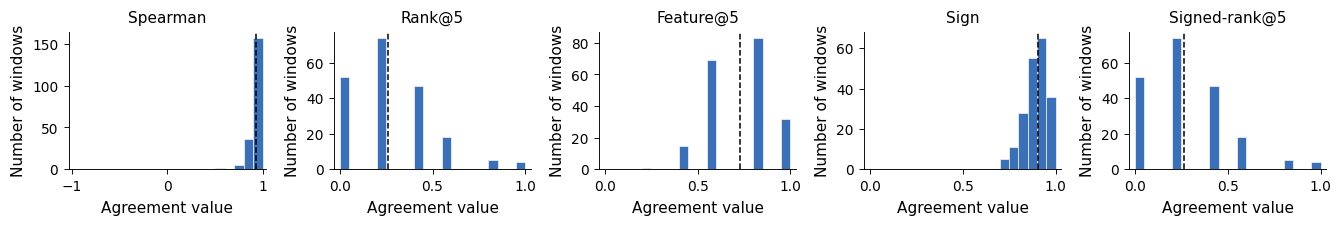

In [16]:
def draw_hist(ax, values, metric, color):
    values = np.asarray(values, float)
    values = values[~np.isnan(values)]
    low = -1 if metric == "spearman" else 0
    ax.hist(values, bins=np.linspace(low, 1, 21), color=color, edgecolor="white", lw=0.4)
    ax.set_xlim(low - 0.03, 1.03)
    ax.axvline(values.mean(), color="k", lw=1.0, ls="--")
    ax.set_xlabel("Agreement value", fontsize=10)
    ax.set_ylabel("Number of windows", fontsize=10)
    ax.tick_params(labelsize=9)


PANEL, ADJUST = (2.45, 2.1), dict(left=0.27, bottom=0.25, right=0.97, top=0.97)
cnn_pair = WITHIN[("cnn", "ig", "occlusion")]
show_panels(lambda ax, m: draw_hist(ax, cnn_pair[m], m, BLUE), METRICS, "hist_within_{}", PANEL, ADJUST, METRIC_LABEL)

## 7. Cross-model agreement results
The same question across architectures: for one method, do the CNN, the LSTM and the hybrid model point to the same sensors for the same window? LRP is not part of this comparison because it is available for one model only.

In [17]:
CROSS_METHODS = ["ig", "occlusion"]
PAIRS = [("cnn", "lstm"), ("cnn", "hybrid"), ("lstm", "hybrid")]
CROSS = {(method, a, b): pair_agreement((a, method), (b, method)) for method in CROSS_METHODS for a, b in PAIRS}

agreement_table([((LABEL[me], f"{LABEL[a]} vs. {LABEL[b]}"), v) for (me, a, b), v in CROSS.items()], ["Method", "Architecture pair"])

Method,Architecture pair,Spearman,Rank@5,Feature@5,Sign,Signed-rank@5
IG,CNN vs. LSTM,0.513 ± 0.221,0.118 ± 0.144,0.410 ± 0.196,0.651 ± 0.110,0.107 ± 0.134
IG,CNN vs. Hybrid,0.518 ± 0.259,0.088 ± 0.119,0.336 ± 0.206,0.710 ± 0.150,0.079 ± 0.116
IG,LSTM vs. Hybrid,0.568 ± 0.286,0.148 ± 0.162,0.533 ± 0.192,0.724 ± 0.137,0.139 ± 0.159
Occlusion,CNN vs. LSTM,0.417 ± 0.343,0.116 ± 0.136,0.401 ± 0.182,0.680 ± 0.175,0.104 ± 0.126
Occlusion,CNN vs. Hybrid,0.418 ± 0.398,0.091 ± 0.132,0.397 ± 0.207,0.688 ± 0.211,0.085 ± 0.130
Occlusion,LSTM vs. Hybrid,0.585 ± 0.296,0.127 ± 0.164,0.551 ± 0.206,0.735 ± 0.160,0.122 ± 0.165


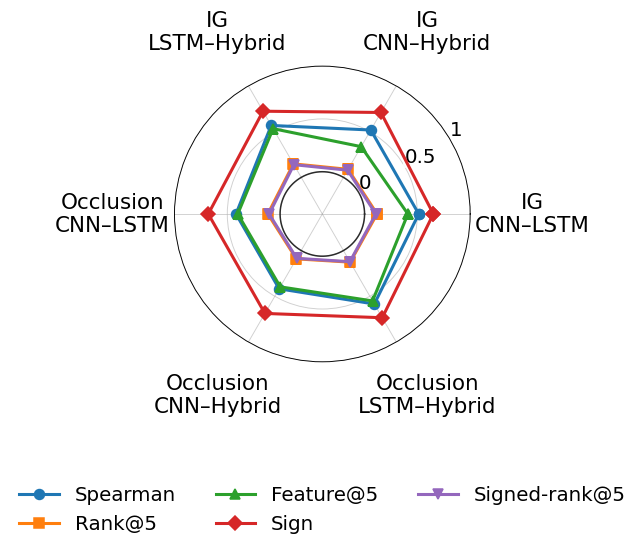

In [18]:
radar(list(CROSS.values()), [f"{LABEL[me]}\n{LABEL[a]}–{LABEL[b]}" for (me, a, b) in CROSS], "radar_cross_model")

Distribution of the five metrics for IG, CNN vs. LSTM.

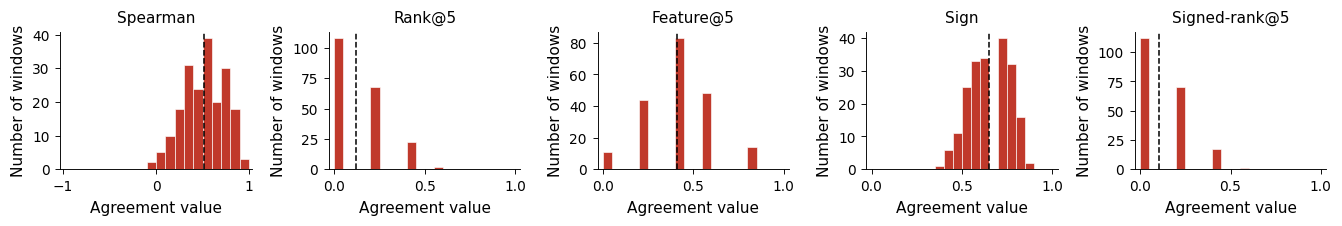

In [19]:
ig_cnn_lstm = CROSS[("ig", "cnn", "lstm")]
show_panels(lambda ax, m: draw_hist(ax, ig_cnn_lstm[m], m, RED), METRICS, "hist_cross_{}", PANEL, ADJUST, METRIC_LABEL)

## 8. Agreement with the physical sensor trends
Each sensor moves in a typical direction while the engine degrades: up (↑), down (↓), or no clear trend (~). The trends are computed here from the training data as the change of each standardized sensor between the first 20 % and the last 20 % of the life of the engines. A change of more than 0.5 standard deviations counts as a trend. The result is the same as the trend column of the sensor table in the paper.

In [20]:
SYMBOL = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30", "φ", "NRf", "NRc", "BPR", "farB",
          "htBleed", "Nf_dmd", "PCNfR_dmd", "W31", "W32"]
PAPER_TREND = dict(zip(range(1, 22), "~↑↑↑~~↓↑↑~↑↓↑↑↑~↑~~↓↓"))     # trend of sensors 1 to 21 as listed in the paper

life = train_df["cycle"] / train_df.groupby("machine_id")["cycle"].transform("max")
change = pd.Series({s: train_df.loc[life >= 0.8, f"sensor_{s}"].mean() - train_df.loc[life <= 0.2, f"sensor_{s}"].mean()
                    for s in range(1, 22)})
trend = change.apply(lambda c: "↑" if c > 0.5 else "↓" if c < -0.5 else "~")
assert trend.to_dict() == PAPER_TREND, "the trends computed from the data differ from the paper"
display(pd.DataFrame({"Symbol": SYMBOL, "Change (SD)": change.round(2).values, "Trend": trend.values}, index=range(1, 22)).T)

,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
Symbol,T2,T24,T30,T50,P2,P15,P30,Nf,Nc,epr,...,φ,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
Change (SD),0.0,1.81,1.78,2.04,0.0,0.33,-1.97,1.65,1.31,0.0,...,-2.01,1.65,1.06,1.93,0.0,1.84,0.0,0.0,-1.9,-1.92
Trend,~,↑,↑,↑,~,~,↓,↑,↑,~,...,↓,↑,↑,↑,~,↑,~,~,↓,↓


**Direction of the explanation.** The RUL falls while the engine ages. A ↑ sensor therefore moves opposite to the RUL, and a higher value of it should lower the predicted RUL. A ↓ sensor moves together with the RUL, and a higher value of it should raise the predicted RUL.

The attributions of IG, Occlusion and LRP are roughly gradient × input. Multiplying an attribution by the input once more gives gradient × input², which has the sign of the gradient. Summed over the 50 time steps of a window, its sign is the direction in which the explanation says the prediction moves when the sensor goes up: negative is expected for ↑ sensors and positive for ↓ sensors. The sensors without a trend are left out, which leaves 14 of the 17 sensors that vary. Three numbers per model and method:

- **Pairs (%)**: share of the 200 windows × 14 sensors with the expected direction (50 % is chance).
- **Weighted (%)**: the same share, with every pair weighted by the size of its effect, so that the sensors the explanation relies on count more.
- **Sensors (of 14)**: number of sensors with the expected direction when the effect is added over all 200 windows.

In [21]:
EXPECTED = {s: (-1 if a == "↑" else 1) for s, a in PAPER_TREND.items() if a != "~"}   # expected sign of d(RUL)/d(sensor)
TREND_CHANNELS = [s + 2 for s in EXPECTED]                                           # sensor s is channel s + 2 (three settings first)
expected = np.array(list(EXPECTED.values()))
X_sample = X_val[IDX].numpy()

TREND = {}
for model_name in MODELS:
    for method in SHOWN[model_name]:
        effect = (maps[(model_name, method)] * X_sample).sum(axis=1)[:, TREND_CHANNELS]     # (windows, 14)
        match = np.sign(effect) == expected
        TREND[(model_name, method)] = {"pairs": 100 * match.mean(),
                                       "weighted": 100 * (np.abs(effect) * match).sum() / np.abs(effect).sum(),
                                       "sensors": int((np.sign(effect.sum(0)) == expected).sum()),
                                       "per_sensor": 100 * match.mean(0),
                                       "against": [f"s{s} {SYMBOL[s - 1]}" for s, e, d in zip(EXPECTED, expected, effect.sum(0)) if np.sign(d) != e]}

trend_table = pd.DataFrame({(LABEL[m], LABEL[k]): {"Pairs (%)": round(v["pairs"], 1), "Weighted (%)": round(v["weighted"], 1),
                                                   "Sensors (of 14)": v["sensors"]} for (m, k), v in TREND.items()}).T
trend_table["Sensors (of 14)"] = trend_table["Sensors (of 14)"].astype(int)
display(trend_table)

Pairs (%)  Weighted (%)  Sensors (of 14)
CNN    IG              62.6          71.8                9
       Occlusion       58.3          60.5                8
       LRP             53.0          56.3                8
LSTM   IG              60.1          81.0               11
       Occlusion       70.5          74.1               12
Hybrid IG              57.3          84.9               11
       Occlusion       71.1          66.8               13

**Per sensor.** Share of the 200 windows in which the direction of the explanation is the expected one, for each of the 14 sensors with a trend (red: below 50 %, blue: above).

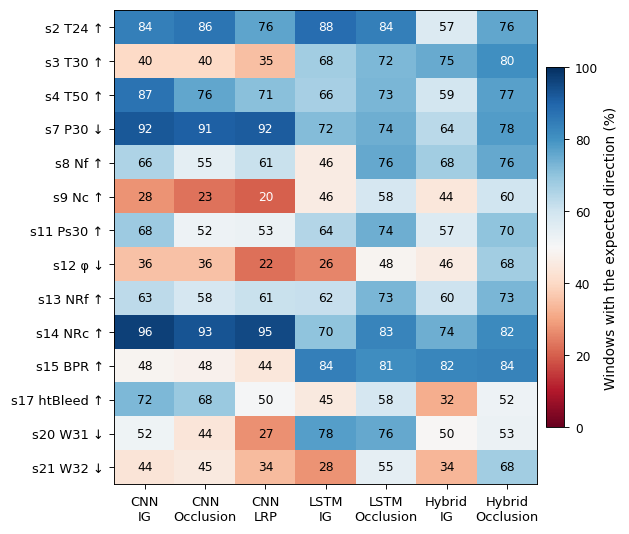

Sensors whose direction over all 200 windows is against the trend:
  CNN IG: s3 T30, s9 Nc, s12 φ, s20 W31, s21 W32
  CNN Occlusion: s3 T30, s9 Nc, s11 Ps30, s12 φ, s20 W31, s21 W32
  CNN LRP: s3 T30, s9 Nc, s11 Ps30, s12 φ, s20 W31, s21 W32
  LSTM IG: s12 φ, s17 htBleed, s21 W32
  LSTM Occlusion: s12 φ, s21 W32
  Hybrid IG: s17 htBleed, s20 W31, s21 W32
  Hybrid Occlusion: s20 W31


In [22]:
def trend_figure():
    keys = list(TREND)
    grid = np.array([TREND[k]["per_sensor"] for k in keys]).T                           # (14 sensors, 7 combinations)
    fig, ax = plt.subplots(figsize=(TEXTWIDTH * 0.8, 4.9))
    image = ax.imshow(grid, cmap="RdBu", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels([f"{LABEL[m]}\n{LABEL[k]}" for m, k in keys], fontsize=8.5)
    ax.set_yticks(range(len(EXPECTED)))
    ax.set_yticklabels([f"s{s} {SYMBOL[s - 1]} {PAPER_TREND[s]}" for s in EXPECTED], fontsize=8.5)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if abs(grid[i, j] - 50) > 28 else "black")
    colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
    colorbar.set_label("Windows with the expected direction (%)", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(True)
    fig.tight_layout()
    save_figure(fig, "trend_agreement")
    plt.show()


trend_figure()
print("Sensors whose direction over all 200 windows is against the trend:")
for (m, k), v in TREND.items():
    print(f"  {LABEL[m]} {LABEL[k]}: {', '.join(v['against'])}")

## 9. Sensitivity and infidelity results
Computed for the first 50 windows of the sample, with Gaussian noise of standard deviation 0.05 (the inputs are standardized).

- **Sensitivity** (stability): the explanation is computed again for a perturbed input; the value is the largest relative change of the map over 3 perturbations, `||A(x + d) - A(x)|| / ||A(x)||`. Lower is more stable.
- **Infidelity** (faithfulness, Yeh et al. 2019): `E[(A(x)·d - (f(x) - f(x - d)))^2]` over 5 perturbations `d`. Lower means that the explanation predicts better how the output changes under perturbation.

The values are saved in `results/cache/eval.npz`.

In [23]:
def noise(seed, shape):
    return torch.randn(shape, generator=torch.Generator().manual_seed(seed)) * SIGMA


def compute_eval(n_eval):
    """sensitivity and infidelity of every shown (model, method) combination for the first n_eval windows"""
    sens = {(m, k): [] for m in MODELS for k in SHOWN[m]}
    infid = {key: [] for key in sens}
    for model_name in MODELS:
        f = FN[model_name]
        for p in range(n_eval):
            x = X_val[IDX[p]:IDX[p] + 1]
            with torch.no_grad():
                y0 = f(x).item()
            for method in SHOWN[model_name]:
                base = maps[(model_name, method)][p]
                worst = 0.0
                for j in range(3):
                    perturbed = attribute(model_name, method, x + noise(10_000 + 97 * p + 13 * j, x.shape))[0]
                    worst = max(worst, np.linalg.norm(perturbed - base) / (np.linalg.norm(base) + 1e-12))
                sens[(model_name, method)].append(worst)
            deltas = [noise(20_000 + 97 * p + 13 * j, x.shape) for j in range(5)]
            with torch.no_grad():
                changes = [y0 - f(x - d).item() for d in deltas]
            for method in SHOWN[model_name]:
                base = maps[(model_name, method)][p]
                infid[(model_name, method)].append(np.mean([(float((base * d.numpy()[0]).sum()) - c) ** 2 for d, c in zip(deltas, changes)]))
        print("sensitivity and infidelity:", model_name, flush=True)
    return {k: np.array(v) for k, v in sens.items()}, {k: np.array(v) for k, v in infid.items()}


EVAL_FILE = f"{CACHE}/eval.npz"
if os.path.exists(EVAL_FILE):
    saved = np.load(EVAL_FILE)
    SENS = {tuple(k.split("__")[1:]): saved[k] for k in saved.files if k.startswith("sens__")}
    INFID = {tuple(k.split("__")[1:]): saved[k] for k in saved.files if k.startswith("infid__")}
else:
    SENS, INFID = compute_eval(N_EVAL)
    np.savez_compressed(EVAL_FILE, **{f"sens__{m}__{k}": v for (m, k), v in SENS.items()},
                        **{f"infid__{m}__{k}": v for (m, k), v in INFID.items()})

# check of the saved values: the first 2 windows are computed again
fresh_sens, fresh_infid = compute_eval(2)
print("largest difference to the cache, sensitivity:", max(float(np.abs(fresh_sens[k] - SENS[k][:2]).max()) for k in fresh_sens),
      "| infidelity:", max(float(np.abs(fresh_infid[k] - INFID[k][:2]).max()) for k in fresh_infid))

sensitivity and infidelity: cnn
sensitivity and infidelity: lstm
sensitivity and infidelity: hybrid
largest difference to the cache, sensitivity: 0.0 | infidelity: 0.0


**Sensitivity and infidelity** over the 50 windows (lower is better for both).

In [24]:
keys = list(SENS)
columns = {"Sensitivity mean": [SENS[k].mean() for k in keys], "Sensitivity std": [SENS[k].std() for k in keys],
           "Infidelity mean": [INFID[k].mean() for k in keys], "Infidelity std": [INFID[k].std() for k in keys]}
eval_table = pd.DataFrame(columns, index=pd.MultiIndex.from_tuples([(LABEL[m], LABEL[k]) for m, k in keys], names=["Model", "Method"]))
display(eval_table.round(3))

Sensitivity mean  Sensitivity std  Infidelity mean  \
Model  Method                                                          
CNN    IG                    0.115            0.022            2.580   
       Occlusion             0.142            0.024            2.335   
       LRP                   0.175            0.054            2.625   
LSTM   IG                    0.184            0.160            0.881   
       Occlusion             0.319            0.348            0.856   
Hybrid IG                    0.134            0.091            0.899   
       Occlusion             0.230            0.233            0.838   

                  Infidelity std  
Model  Method                     
CNN    IG                  1.767  
       Occlusion           1.761  
       LRP                 1.999  
LSTM   IG                  1.151  
       Occlusion           1.359  
Hybrid IG                  1.357  
       Occlusion           1.642

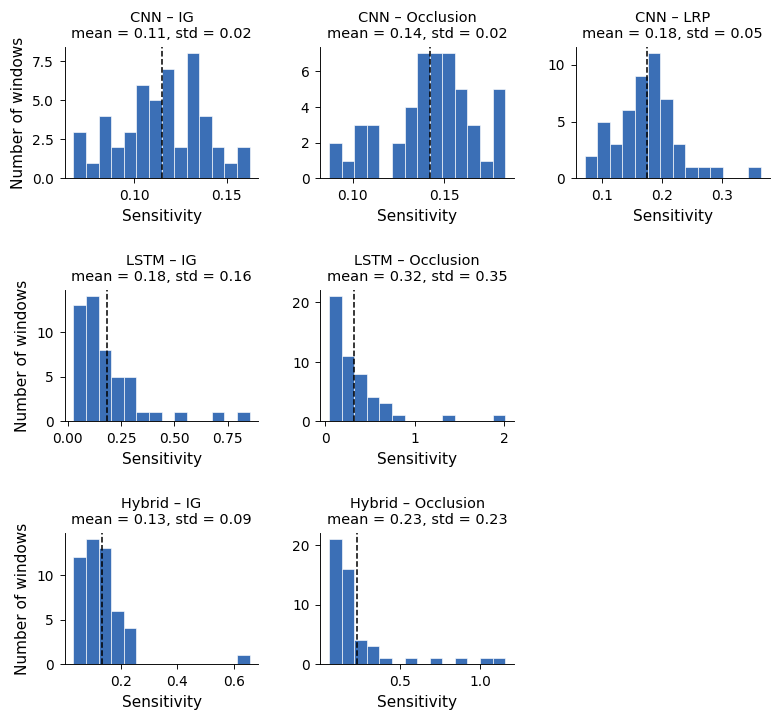

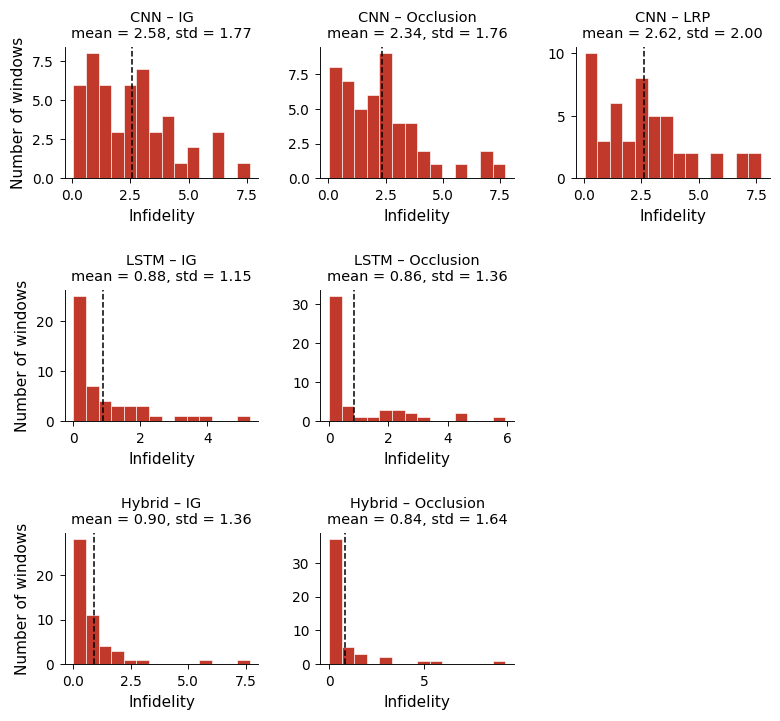

In [25]:
def eval_histograms(values, xlabel, color, name):
    fig, axes = plt.subplots(3, 3, figsize=(TEXTWIDTH, 6.6))
    for r, model_name in enumerate(MODELS):
        for c, method in enumerate(METHODS):
            ax = axes[r, c]
            if method not in SHOWN[model_name]:
                ax.axis("off")
                continue
            v = values[(model_name, method)]
            ax.hist(v, bins=14, color=color, edgecolor="white", lw=0.4)
            ax.axvline(v.mean(), color="k", lw=1.0, ls="--")
            ax.set_title(f"{LABEL[model_name]} – {LABEL[method]}\nmean = {v.mean():.2f}, std = {v.std():.2f}", fontsize=9.5)
            ax.set_xlabel(xlabel, fontsize=10)
            ax.tick_params(labelsize=9)
            if c == 0:
                ax.set_ylabel("Number of windows", fontsize=10)
    fig.subplots_adjust(hspace=0.85, wspace=0.32, top=0.93, bottom=0.08, left=0.09, right=0.98)
    save_figure(fig, name)
    plt.show()


eval_histograms(SENS, "Sensitivity", BLUE, "eval_sensitivity_hist")
eval_histograms(INFID, "Infidelity", RED, "eval_infidelity_hist")

## 10. Activation maximization results
Gradient ascent on the input itself finds the synthetic window to which a model gives the highest RUL: zero start, Adam, 500 steps, learning rate 0.05. Without a restriction the input drifts far outside the range of real data, so the paper restricts every channel to ±2 standard deviations of the training data (the inputs are standardized) by clipping after each step; the constant channels are fixed at zero. The profiles of the three models are compared with the Spearman correlation of their per-sensor values (the mean over the 50 time steps, 17 sensors).

In [26]:
def activation_maximization(f, bound=None, steps=500, lr=0.05):
    """bound: None (unrestricted) or the number of standard deviations the channels may reach"""
    window = torch.zeros(1, WINDOW, 24, requires_grad=True)
    optimizer = torch.optim.Adam([window], lr=lr)
    if bound is not None:
        high = torch.full((1, 1, 24), float(bound))
        high[..., CONSTANT] = 0
    for _ in range(steps):
        optimizer.zero_grad()
        (-f(window)).sum().backward()
        optimizer.step()
        if bound is not None:
            with torch.no_grad():
                window.copy_(torch.max(torch.min(window, high), -high))
    return window.detach().numpy().squeeze()


AM = {(m, b): activation_maximization(FN[m], b) for m in MODELS for b in (None, 1.0, AM_BOX_SD, 3.0)}

In [27]:
profile = lambda m, b: AM[(m, b)].mean(0)[ACTIVE]
settings = {"unrestricted": None, "±1 SD": 1.0, "±2 SD (paper)": AM_BOX_SD, "±3 SD": 3.0}
correlation = pd.DataFrame({name: [spearmanr(profile(a, b), profile(c, b))[0] for a, c in PAIRS] for name, b in settings.items()},
                           index=[f"{LABEL[a]} vs. {LABEL[c]}" for a, c in PAIRS])
print("Spearman correlation of the per-sensor profiles")
display(correlation.round(2))

with torch.no_grad():
    predicted = pd.DataFrame({name: [FN[m](torch.tensor(AM[(m, b)])[None]).item() for m in MODELS] for name, b in settings.items()},
                             index=[LABEL[m] for m in MODELS])
print("Predicted RUL of the synthetic window (cycles)")
display(predicted.round(0))
print("Largest absolute value of the profile (standard deviations):",
      {LABEL[m]: {n: round(float(np.abs(AM[(m, b)].mean(0)).max()), 1) for n, b in settings.items() if n in ("unrestricted", "±2 SD (paper)")} for m in MODELS})

Spearman correlation of the per-sensor profiles


,unrestricted,±1 SD,±2 SD (paper),±3 SD
CNN vs. LSTM,0.26,0.47,0.36,0.35
CNN vs. Hybrid,-0.21,-0.14,-0.16,-0.14
LSTM vs. Hybrid,-0.59,-0.31,-0.39,-0.44


Predicted RUL of the synthetic window (cycles)


,unrestricted,±1 SD,±2 SD (paper),±3 SD
CNN,17068.0,604.0,1123.0,1649.0
LSTM,114.0,114.0,114.0,114.0
Hybrid,120.0,120.0,120.0,120.0


Largest absolute value of the profile (standard deviations): {'CNN': {'unrestricted': 23.9, '±2 SD (paper)': 1.4}, 'LSTM': {'unrestricted': 1.5, '±2 SD (paper)': 1.2}, 'Hybrid': {'unrestricted': 0.9, '±2 SD (paper)': 0.7}}


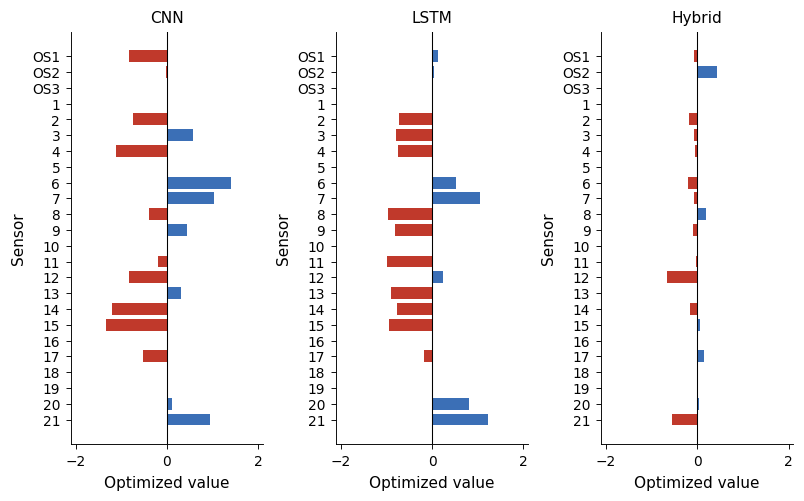

In [28]:
def draw_actmax(ax, model_name):
    values = AM[(model_name, AM_BOX_SD)].mean(0)
    colors = ["#bbbbbb" if i in CONSTANT else (BLUE if values[i] >= 0 else RED) for i in range(24)]
    ax.barh(np.arange(24), values, color=colors, height=0.75)
    ax.axvline(0, color="k", lw=0.7)
    ax.set_yticks(np.arange(24))
    ax.set_yticklabels(SENSOR_NUM, fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(-AM_BOX_SD * 1.05, AM_BOX_SD * 1.05)
    ax.set_xlabel("Optimized value", fontsize=10)
    ax.set_ylabel("Sensor", fontsize=10)
    ax.tick_params(labelsize=9)


show_panels(draw_actmax, MODELS, "actmax_{}", (2.45, 4.6), dict(left=0.24, bottom=0.1, right=0.97, top=0.99), LABEL)

## 11. Model prediction sensitivity results
Separately from the explanations: how much does the predicted RUL change when the input is perturbed? Each of the first 50 windows is perturbed with Gaussian noise (standard deviation 0.05) ten times, and the absolute change of the predicted RUL is recorded in cycles.

,CNN,LSTM,Hybrid
mean,0.979,0.424,0.500
median,0.800,0.160,0.193
std,0.788,0.664,0.728


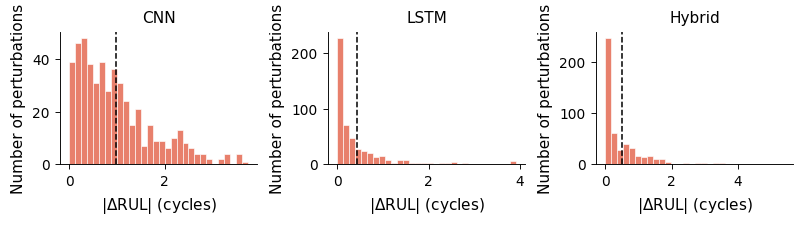

In [29]:
OUTPUT_CHANGE = {}
for model_name in MODELS:
    changes = []
    for p in range(N_EVAL):
        x = X_val[IDX[p]:IDX[p] + 1]
        with torch.no_grad():
            y0 = FN[model_name](x).item()
            changes += [abs(FN[model_name](x + noise(30_000 + 97 * p + 13 * j, x.shape)).item() - y0) for j in range(10)]
    OUTPUT_CHANGE[model_name] = np.array(changes)

display(pd.DataFrame({LABEL[m]: {"mean": v.mean(), "median": np.median(v), "std": v.std()} for m, v in OUTPUT_CHANGE.items()}).round(3))


def draw_output_change(ax, model_name):
    v = OUTPUT_CHANGE[model_name]
    ax.hist(v, bins=30, color="#e8806c", edgecolor="white", lw=0.4)
    ax.axvline(v.mean(), color="k", lw=1.0, ls="--")
    ax.set_xlabel(r"$|\Delta$RUL$|$ (cycles)", fontsize=10)
    ax.set_ylabel("Number of perturbations", fontsize=10)
    ax.tick_params(labelsize=9)


show_panels(draw_output_change, MODELS, "output_noise_{}", PANEL, ADJUST, LABEL)

## 12. Trust study results
31 participants rated their trust in the RUL prediction from 1 to 5 at seven of the eight stages of the dashboard, which discloses the explanation and the context step by step. The questionnaire answers are in `data/AI Predictive Maintenance.csv`.

In [30]:
survey = pd.read_csv(f"{DATA}/AI Predictive Maintenance.csv")
survey_cols = survey.columns.tolist()
STAGES = ["Stage 1", "Stage 3", "Stage 4", "Stage 5", "Stage 6", "Stage 7", "Stage 8"]
trust = survey[[survey_cols[i] for i in (1, 4, 5, 6, 7, 8, 9)]].values.astype(float)
N, K = trust.shape

# mean trust per stage
display(pd.DataFrame({"Mean trust": trust.mean(0).round(2), "Std": trust.std(0, ddof=1).round(2)}, index=STAGES))

# Wilcoxon signed-rank tests between the stages (one-tailed: trust increases)
tests = []
for name, i, j in [("Stage 1 -> 3", 0, 1), ("Stage 3 -> 4", 1, 2), ("Stage 4 -> 5", 2, 3), ("Stage 5 -> 6", 3, 4),
                   ("Stage 6 -> 7", 4, 5), ("Stage 7 -> 8", 5, 6), ("Stage 1 -> 8", 0, 6)]:
    diff = trust[:, j] - trust[:, i]
    statistic, p = stats.wilcoxon(diff[diff != 0], alternative="greater")
    tests.append((name, statistic, p))
display(pd.DataFrame(tests, columns=["Comparison", "W", "p (one-tailed)"]).set_index("Comparison").round(6))

# Friedman test, Kendall's W (corrected for ties), effect size and reliability
friedman, p_friedman = stats.friedmanchisquare(*[trust[:, i] for i in range(K)])
ranks = np.apply_along_axis(rankdata, 1, trust)
S = np.sum((ranks.sum(0) - N * (K + 1) / 2) ** 2)
ties = sum(sum(t ** 3 - t for t in np.unique(r, return_counts=True)[1]) for r in ranks)
kendall_w = 12 * S / (N ** 2 * (K ** 3 - K) - N * ties)
difference = trust[:, 6] - trust[:, 0]
alpha = K / (K - 1) * (1 - trust.var(0, ddof=1).sum() / trust.sum(1).var(ddof=1))
print(f"Friedman chi2({K - 1}) = {friedman:.2f}, p = {p_friedman:.2e}")
print(f"Kendall's W (tie-corrected) = {kendall_w:.3f}")
print(f"Cohen's d_z, stage 1 -> 8 = {difference.mean() / difference.std(ddof=1):.2f}")
print(f"Cronbach's alpha = {alpha:.2f}")

,Mean trust,Std
Stage 1,3.03,0.87
Stage 3,3.42,0.72
Stage 4,3.48,0.81
Stage 5,3.58,0.85
Stage 6,4.06,0.89
Stage 7,4.06,0.73
Stage 8,4.32,0.70


,W,p (one-tailed)
Comparison,,
Stage 1 -> 3,155.0,0.021922
Stage 3 -> 4,33.0,0.376953
Stage 4 -> 5,30.0,0.253906
Stage 5 -> 6,105.0,0.000137
Stage 6 -> 7,32.5,0.582031
Stage 7 -> 8,40.5,0.017578
Stage 1 -> 8,271.5,0.000017


Friedman chi2(6) = 74.17, p = 5.68e-14
Kendall's W (tie-corrected) = 0.399
Cohen's d_z, stage 1 -> 8 = 1.14
Cronbach's alpha = 0.82


**Ranking of the six dashboard elements** by the participants (Borda count: the first choice of a participant gets 6 points, the last gets 1).

In [31]:
borda = Counter()
for _, row in survey.iterrows():
    for position, item in enumerate([str(row[c]).strip() for c in survey_cols[10:16]]):
        borda[item] += 6 - position
display(pd.Series(dict(borda.most_common()), name="Borda points").to_frame())

,Borda points
Plots of sensor measurements against healthy values,139
Table with historical data,133
Hover functionality over heatmap,125
Green-Red Heatmap (sensor measurement with directionality),107
White-Red Heatmap (sensor measurements),91
Bar chart (sensors),56
